# Персональные рекомендации музыкальных треков

## Основные результаты

Обработаны 222 629 898 событий от 1 373 221 пользователя для 1 000 000 треков. Невалидных обязательных полей и точных дубликатов событий не найдено. Пропуски и неизвестные атрибуты треков отмечены отдельно.

На тестовом периоде 16–31 декабря 2022 года итоговое ранжирование получило recall@20=0.02312 и precision@20=0.00946. Для ALS recall@20=0.02129, для популярных треков — 0.00780. Охват каталога итоговой выдачей — 3.22%, средняя доля новых для пользователя треков — 85.40%. Сравнение проведено на одинаковых 783 525 тестовых пользователях, включая холодных.

Параметры моделей фиксированы, подбор гиперпараметров не проводился. Шесть итоговых Parquet-файлов сохранены в персональном S3-бакете.

Ноутбук содержит этапы 1–3 проекта и рассчитан на последовательный запуск
на ПК или виртуальной машине с достаточной памятью. В Jupyter Hub загружается
готовый ноутбук с выводами. Следующие ячейки сохраняют вспомогательные файлы,
чтобы работу можно было передать одним файлом. Их содержимое совпадает
с файлами проекта в репозитории.

Перед запуском требуется доступ к персональному S3-бакету через переменные
окружения или профиль AWS. На Windows также поддерживается уже настроенное
подключение CS Browser через `S3_BROWSER_ACCOUNT`. Секретные ключи в ячейки
вводить не нужно.


In [1]:
%%writefile requirements.txt
numpy==1.26.4
pandas==2.1.1
pyarrow==13.0.0
scipy==1.11.3
scikit-learn==1.3.2
implicit==0.7.2
catboost==1.2.2
faiss-cpu==1.7.4; sys_platform != "win32"
faiss-cpu==1.13.2; sys_platform == "win32"
matplotlib==3.8.0
seaborn==0.12.2
boto3==1.34.162
requests==2.31.0
duckdb==1.1.3
fastapi==0.104.1
uvicorn==0.24.0.post1
httpx==0.27.2
nbformat==5.10.4
nbclient==0.10.0
jupyterlab==4.2.5
ipykernel==6.29.5


Overwriting requirements.txt


In [2]:
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


### Вспомогательный файл `download_data.py`

In [3]:
%%writefile download_data.py
"""Загрузка исходных данных проекта."""

from pathlib import Path

import pyarrow.parquet as pq
import requests


DATA_URLS = {
    "tracks.parquet": "https://mle-data.storage.yandexcloud.net/ym/tracks.parquet",
    "catalog_names.parquet": "https://mle-data.storage.yandexcloud.net/ym/catalog_names.parquet",
    "interactions.parquet": "https://mle-data.storage.yandexcloud.net/ym/interactions.parquet",
}


def download_data(data_dir="data/raw"):
    data_dir = Path(data_dir)
    data_dir.mkdir(parents=True, exist_ok=True)
    paths = {}

    for filename, url in DATA_URLS.items():
        path = data_dir / filename
        if path.exists():
            try:
                pq.read_metadata(path)
                print("Файл уже загружен:", filename)
                paths[filename] = path
                continue
            except Exception:
                print("Повторная загрузка файла:", filename)

        partial_path = path.with_suffix(path.suffix + ".part")
        with requests.Session() as session:
            head = session.head(url, timeout=(15, 30))
            head.raise_for_status()
            total_size = int(head.headers["Content-Length"])
            start = partial_path.stat().st_size if partial_path.exists() else 0
            if start > total_size:
                raise RuntimeError("Размер частично загруженного файла превышает исходный: " + filename)
            # Небольшие диапазоны устойчивее одного запроса на файл размером более гигабайта.
            while start < total_size:
                for attempt in range(3):
                    start = partial_path.stat().st_size if partial_path.exists() else 0
                    end = min(start + 32 * 1024 * 1024 - 1, total_size - 1)
                    try:
                        with session.get(
                            url, headers={"Range": "bytes={}-{}".format(start, end)},
                            stream=True, timeout=(15, 90),
                        ) as response:
                            response.raise_for_status()
                            expected_range = "bytes {}-{}/{}".format(start, end, total_size)
                            if response.status_code != 206 or response.headers.get("Content-Range") != expected_range:
                                raise RuntimeError("Сервер вернул неверный диапазон байтов: " + filename)
                            with partial_path.open("ab") as file:
                                for block in response.iter_content(chunk_size=1024 * 1024):
                                    if block:
                                        file.write(block)
                        start = partial_path.stat().st_size
                        print("{}: {:.1f}% ({:.0f} МБ)".format(
                            filename, 100 * start / total_size, start / 1024 ** 2), flush=True)
                        break
                    except (requests.RequestException, OSError) as error:
                        if attempt == 2:
                            raise RuntimeError("Не удалось загрузить {}. Повторите запуск загрузки.".format(filename)) from error
                        print("Соединение прервано. Повторная попытка для", filename, flush=True)
        if partial_path.stat().st_size != total_size:
            raise RuntimeError("Не совпал размер загруженного файла: " + filename)
        pq.read_metadata(partial_path)
        partial_path.replace(path)
        print("Загружен файл:", filename)
        paths[filename] = path
    return paths


if __name__ == "__main__":
    download_data()


Overwriting download_data.py


### Вспомогательный файл `storage.py`

In [4]:
%%writefile storage.py
"""Сохранение результатов проекта в персональный S3-бакет."""

import os
import re
import subprocess
import tempfile
from pathlib import Path, PurePosixPath

import boto3
from botocore.exceptions import BotoCoreError, ClientError, ProfileNotFound


class BrowserStorage:
    """Доступ через уже настроенный аккаунт CS Browser в Windows."""

    def __init__(self, account):
        self.account = account
        self.executable = Path(os.getenv(
            "S3_BROWSER_CLI", r"C:\Program Files\CS Browser\s3browser-cli.exe"
        ))
        if not self.executable.is_file():
            raise FileNotFoundError("Не найден командный интерфейс CS Browser.")

    def run(self, *arguments):
        result = subprocess.run(
            [str(self.executable), "/file", arguments[0], self.account, *arguments[1:]],
            capture_output=True, text=True, encoding="utf-8", errors="replace",
            creationflags=getattr(subprocess, "CREATE_NO_WINDOW", 0),
        )
        output = result.stdout + result.stderr
        if result.returncode or re.search(r"\[E\]|\bERROR\b|\bFAILED\b", output, re.I):
            raise RuntimeError("Ошибка CS Browser:\n" + output[-2500:])
        return output

    def head_bucket(self, Bucket):
        self.run("list", Bucket + "/recsys", "s")

    def head_object(self, Bucket, Key):
        key = PurePosixPath(Key)
        folder = Bucket if str(key.parent) == "." else Bucket + "/" + str(key.parent)
        output = self.run("list", folder, "s")
        match = re.search(r"^" + re.escape(key.name) + r"\s+(\d+)\s*$", output, re.M)
        if match is None:
            raise FileNotFoundError("Объект не найден в S3: " + Key)
        return {"ContentLength": int(match.group(1))}

    def upload_file(self, filename, bucket, key):
        path, object_key = Path(filename), PurePosixPath(key)
        if path.name != object_key.name:
            raise ValueError("При загрузке через CS Browser имя файла должно совпадать с именем объекта.")
        folder = bucket if str(object_key.parent) == "." else bucket + "/" + str(object_key.parent)
        self.run("upload", str(path.resolve()), folder)

    def download_file(self, bucket, key, filename):
        path = Path(filename).resolve()
        path.parent.mkdir(parents=True, exist_ok=True)
        with tempfile.TemporaryDirectory(dir=path.parent) as temporary:
            directory = Path(temporary).resolve()
            if directory.parent != path.parent:
                raise ValueError("Временная папка должна находиться рядом с целевым файлом.")
            self.run("download", bucket + "/" + key, str(directory))
            downloaded = directory / PurePosixPath(key).name
            if not downloaded.is_file():
                raise FileNotFoundError("CS Browser не сохранил скачанный файл.")
            downloaded.replace(path)


def ensure_storage():
    bucket = os.getenv("S3_BUCKET", "").strip()
    if not bucket:
        raise RuntimeError(
            "Не задан S3_BUCKET. Укажите имя персонального бакета в переменной "
            "окружения перед запуском ноутбука. Ключи доступа в код добавлять не нужно."
        )

    browser_account = os.getenv("S3_BROWSER_ACCOUNT", "").strip()
    if browser_account:
        client = BrowserStorage(browser_account)
        client.head_bucket(Bucket=bucket)
        return client, bucket

    profile = os.getenv("AWS_PROFILE") or None
    endpoint = os.getenv("S3_ENDPOINT_URL", "https://storage.yandexcloud.net")
    try:
        session = boto3.Session(profile_name=profile)
        client = session.client("s3", endpoint_url=endpoint, region_name=session.region_name or "ru-central1")
        client.head_bucket(Bucket=bucket)
    except ProfileNotFound as error:
        raise RuntimeError("Не найден профиль AWS_PROFILE. Проверьте настройку S3 на виртуальной машине.") from error
    except (BotoCoreError, ClientError) as error:
        raise RuntimeError(
            "Не удалось подключиться к S3-бакету. Проверьте S3_BUCKET, "
            "S3_ENDPOINT_URL и доступ к бакету в настройках окружения."
        ) from error
    return client, bucket


def upload_file(path, key):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError("Файл для загрузки не найден: {}".format(path))
    client, bucket = ensure_storage()
    client.upload_file(str(path), bucket, key)
    saved_size = client.head_object(Bucket=bucket, Key=key)["ContentLength"]
    if saved_size != path.stat().st_size:
        raise RuntimeError("Размер сохранённого в S3 файла не совпал с исходным.")
    return "s3://{}/{}".format(bucket, key)


def download_file(key, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    client, bucket = ensure_storage()
    client.download_file(bucket, key, str(path))
    if client.head_object(Bucket=bucket, Key=key)["ContentLength"] != path.stat().st_size:
        raise RuntimeError("Размер скачанного из S3 файла не совпал с размером объекта.")
    return path


Overwriting storage.py


### Вспомогательный файл `data_preparation.py`

In [5]:
%%writefile data_preparation.py
"""Подготовка и первичный анализ музыкальных данных."""

from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq


def estimate_memory(data_dir):
    metadata = pq.ParquetFile(Path(data_dir) / "interactions.parquet")
    row_bytes = 0
    for field in metadata.schema_arrow:
        if pa.types.is_integer(field.type) or pa.types.is_floating(field.type):
            row_bytes += field.type.bit_width // 8
        elif pa.types.is_timestamp(field.type):
            row_bytes += 8
        else:
            row_bytes += 40
    # Во время преобразований одновременно могут существовать несколько массивов.
    estimate_gb = metadata.metadata.num_rows * row_bytes * 2.5 / 1024 ** 3
    print("Приблизительная оценка памяти для обработки interactions: {:.1f} ГиБ.".format(estimate_gb))
    print("Это оценка: фактический расход зависит от типов и промежуточных таблиц.")
    return estimate_gb


def load_raw_data(data_dir="data/raw"):
    data_dir = Path(data_dir)
    estimate_memory(data_dir)
    tracks = pd.read_parquet(data_dir / "tracks.parquet")
    catalog_names = pd.read_parquet(data_dir / "catalog_names.parquet")
    interactions = pd.read_parquet(data_dir / "interactions.parquet")
    return tracks, catalog_names, interactions


def _sql_path(path):
    return "'" + str(Path(path).resolve()).replace("'", "''") + "'"


def _connect_events(path):
    connection = duckdb.connect()
    temporary_dir = Path(path).parent / "tmp"
    temporary_dir.mkdir(parents=True, exist_ok=True)
    connection.execute("SET threads = 4")
    connection.execute("SET memory_limit = '3GB'")
    connection.execute("SET preserve_insertion_order = false")
    connection.execute("SET TimeZone = 'UTC'")
    connection.execute("SET temp_directory = " + _sql_path(temporary_dir))
    return connection


def event_summary(events_path):
    """Небольшая сводка; сами события в pandas не загружаются."""
    with _connect_events(events_path) as connection:
        return connection.execute("""
            SELECT COUNT(*) AS rows, COUNT(DISTINCT user_id) AS users,
                   MIN(started_at) AS min_date, MAX(started_at) AS max_date
            FROM read_parquet({})
        """.format(_sql_path(events_path))).df()


def prepare_data_from_files(raw_dir="data/raw", prepared_dir="data/prepared"):
    """Готовит полный набор событий средствами DuckDB с выгрузкой на диск."""
    raw_dir, prepared_dir = Path(raw_dir), Path(prepared_dir)
    prepared_dir.mkdir(parents=True, exist_ok=True)
    events_path = prepared_dir / "events.parquet"
    source_path = raw_dir / "interactions.parquet"
    with _connect_events(events_path) as connection:
        connection.execute("CREATE TEMP VIEW raw_events AS SELECT * FROM read_parquet({})".format(_sql_path(source_path)))
        # Равенство с исходным числом не даёт округлить дробный ID при CAST.
        connection.execute("""
            CREATE TEMP VIEW checked_events AS
            SELECT TRY_CAST(user_id AS INTEGER) AS user_id,
                   TRY_CAST(track_id AS INTEGER) AS item_id,
                   TRY_CAST(track_seq AS SMALLINT) AS track_seq,
                   TRY_CAST(started_at AS TIMESTAMP_NS) AS started_at,
                   COALESCE(TRY_CAST(user_id AS DOUBLE) = TRY_CAST(user_id AS INTEGER), FALSE) AS valid_user,
                   COALESCE(TRY_CAST(track_id AS DOUBLE) = TRY_CAST(track_id AS INTEGER), FALSE) AS valid_item,
                   COALESCE(TRY_CAST(track_seq AS DOUBLE) = TRY_CAST(track_seq AS SMALLINT)
                            AND TRY_CAST(track_seq AS SMALLINT) >= 0, FALSE) AS valid_sequence
            FROM raw_events
        """)
        report = connection.execute("""
            SELECT COUNT(*) AS raw_rows,
                   COUNT(*) FILTER (WHERE NOT valid_user) AS invalid_user_ids,
                   COUNT(*) FILTER (WHERE NOT valid_item) AS invalid_item_ids,
                   COUNT(*) FILTER (WHERE NOT valid_sequence) AS invalid_track_seq,
                   COUNT(*) FILTER (WHERE started_at IS NULL) AS invalid_dates,
                   COUNT(*) FILTER (WHERE NOT (valid_user AND valid_item AND valid_sequence)
                                         OR started_at IS NULL) AS invalid_required_rows_removed
            FROM checked_events
        """).df().iloc[0].map(int).to_dict()
        # Удаляем только совпадения всех четырёх полей. Другие прослушивания пары остаются.
        connection.execute("""
            COPY (
                SELECT DISTINCT user_id, item_id, track_seq, started_at
                FROM checked_events
                WHERE valid_user AND valid_item AND valid_sequence AND started_at IS NOT NULL
            ) TO {} (FORMAT PARQUET, COMPRESSION ZSTD, ROW_GROUP_SIZE 1000000)
        """.format(_sql_path(events_path)))
        rows = pq.ParquetFile(events_path).metadata.num_rows
        report["rows"] = rows
        report["exact_duplicates_removed"] = report["raw_rows"] - report["invalid_required_rows_removed"] - rows
        report["repeat_listens_kept"] = int(connection.execute("""
            SELECT COALESCE(SUM(listens - 1), 0) FROM (
                SELECT COUNT(*) AS listens FROM read_parquet({}) GROUP BY user_id, item_id
            )
        """.format(_sql_path(events_path))).fetchone()[0])
        event_item_ids = connection.execute("SELECT DISTINCT item_id FROM read_parquet({})".format(_sql_path(events_path))).fetchnumpy()["item_id"]
        report["unique_items"] = len(event_item_ids)

    tracks = pd.read_parquet(raw_dir / "tracks.parquet")
    catalog_names = pd.read_parquet(raw_dir / "catalog_names.parquet")
    track_ids, valid_ids = _id_values(tracks["track_id"])
    missing_items = np.setdiff1d(event_item_ids, track_ids.loc[valid_ids].to_numpy())
    if len(missing_items):
        added_tracks = pd.DataFrame({"track_id": missing_items})
        for field in ["artists", "albums", "genres"]:
            added_tracks[field] = [[] for _ in range(len(added_tracks))]
        tracks = pd.concat([tracks, added_tracks], ignore_index=True)
    empty_events = pd.DataFrame({
        "user_id": pd.Series(dtype="int32"), "track_id": pd.Series(dtype="int32"),
        "track_seq": pd.Series(dtype="int16"), "started_at": pd.Series(dtype="datetime64[ns]"),
    })
    items, _, quality_report = prepare_data(tracks, catalog_names, empty_events)
    quality_report["items"]["missing_tracks_added"] = len(missing_items)
    quality_report["events"] = report
    items.to_parquet(prepared_dir / "items.parquet", index=False)
    return items, events_path, quality_report


def _id_values(values):
    numbers = pd.to_numeric(values, errors="coerce")
    valid = numbers.notna()
    if not pd.api.types.is_integer_dtype(numbers.dtype):
        valid &= np.isfinite(numbers) & (numbers % 1 == 0)
    return numbers, valid


def _compact_ids(values):
    if len(values) == 0:
        return values.astype("int64")
    limits = np.iinfo(np.int32)
    wide_limits = np.iinfo(np.int64)
    if values.min() < wide_limits.min or values.max() > wide_limits.max:
        raise ValueError("Идентификатор не помещается в целый тип int64.")
    dtype = "int32" if values.min() >= limits.min and values.max() <= limits.max else "int64"
    return values.astype(dtype)


def _id_list(value):
    if not isinstance(value, (list, tuple, np.ndarray)):
        return []
    result = []
    for item in value:
        if pd.isna(item) or isinstance(item, (bool, np.bool_)):
            continue
        try:
            number = int(item)
        except (TypeError, ValueError, OverflowError):
            continue
        if isinstance(item, (float, np.floating)) and number != item:
            continue
        if number not in result:
            result.append(number)
    return result


def prepare_data(tracks, catalog_names, interactions):
    report = {"items": {}, "events": {}, "catalog": {}, "attributes": {}}
    items = tracks.rename(columns={"track_id": "item_id"}, copy=False)
    item_ids, valid_items = _id_values(items["item_id"])
    report["items"]["invalid_ids_removed"] = int((~valid_items).sum())
    if not valid_items.all():
        items = items.loc[valid_items].copy()
    items["item_id"] = _compact_ids(item_ids.loc[valid_items])

    fields = ["artists", "albums", "genres"]
    for field in fields:
        items[field] = items[field].map(_id_list)

    duplicate_items = items[items.duplicated("item_id", keep=False)]
    report["items"]["duplicate_ids_merged"] = int(items.duplicated("item_id").sum())
    for item_id, group in duplicate_items.groupby("item_id", sort=False):
        first_index = group.index[0]
        for field in fields:
            items.at[first_index, field] = list(dict.fromkeys(item for values in group[field] for item in values))
    if len(duplicate_items):
        items = items.drop_duplicates("item_id").reset_index(drop=True)

    event_columns = ["user_id", "item_id", "track_seq", "started_at"]
    events = interactions.rename(columns={"track_id": "item_id"}, copy=False)
    extra_columns = [column for column in events.columns if column not in event_columns]
    if extra_columns:
        events = events.drop(columns=extra_columns)
    report["events"]["raw_rows"] = len(events)
    valid_events = pd.Series(True, index=events.index)
    for column in ["user_id", "item_id", "track_seq"]:
        values, valid = _id_values(events[column])
        events[column] = values
        valid_events &= valid
    events["started_at"] = pd.to_datetime(events["started_at"], errors="coerce", utc=True).dt.tz_convert(None)
    valid_events &= events["started_at"].notna() & (events["track_seq"] >= 0)
    report["events"]["invalid_required_rows_removed"] = int((~valid_events).sum())
    if not valid_events.all():
        events = events.loc[valid_events].copy()
    for column in ["user_id", "item_id", "track_seq"]:
        events[column] = _compact_ids(events[column])
    duplicates = events.duplicated(event_columns)
    report["events"]["exact_duplicates_removed"] = int(duplicates.sum())
    if duplicates.any():
        events = events.loc[~duplicates].reset_index(drop=True)
    report["events"]["repeat_listens_kept"] = int(events.duplicated(["user_id", "item_id"]).sum())
    report["events"]["rows"] = len(events)

    missing_items = np.setdiff1d(events["item_id"].unique(), items["item_id"].to_numpy())
    report["items"]["missing_tracks_added"] = len(missing_items)
    if len(missing_items):
        added_items = pd.DataFrame({"item_id": missing_items})
        for field in fields:
            added_items[field] = [[] for _ in range(len(added_items))]
        items = pd.concat([items, added_items], ignore_index=True)
    items["item_id"] = _compact_ids(items["item_id"])

    catalog = catalog_names[["id", "type", "name"]].copy()
    catalog_ids, valid_catalog = _id_values(catalog["id"])
    report["catalog"]["invalid_ids_removed"] = int((~valid_catalog).sum())
    catalog = catalog.loc[valid_catalog].copy()
    catalog["id"] = _compact_ids(catalog_ids.loc[valid_catalog])
    aliases = {"tracks": "track", "artists": "artist", "albums": "album", "genres": "genre"}
    catalog["type"] = catalog["type"].astype(str).str.strip().str.lower().replace(aliases)
    report["catalog"]["duplicate_type_ids"] = int(catalog.duplicated(["type", "id"]).sum())
    known_names = catalog["name"].notna() & catalog["name"].astype(str).str.strip().ne("")
    # Сначала убираем пустое имя, иначе оно может скрыть корректную запись того же ID.
    catalog = catalog.loc[known_names]
    catalog = catalog.drop_duplicates(["type", "id"])
    lookups = {}
    for kind in ["track", "artist", "album", "genre"]:
        selected = catalog.loc[catalog["type"] == kind, ["id", "name"]]
        lookups[kind] = selected.set_index("id")["name"].to_dict()

    items["name"] = items["item_id"].map(lookups["track"])
    report["items"]["unknown_names"] = int(items["name"].isna().sum())
    missing_names = items["name"].isna()
    items.loc[missing_names, "name"] = items.loc[missing_names, "item_id"].map(lambda value: "Неизвестный трек {}".format(value))
    for field, kind, label in [("artists", "artist", "исполнитель"), ("albums", "album", "альбом"), ("genres", "genre", "жанр")]:
        lookup = lookups[kind]
        unknown = items[field].map(lambda values: any(value not in lookup for value in values))
        empty = items[field].map(len).eq(0)
        report["attributes"][field] = {"empty_tracks": int(empty.sum()), "unknown_id_tracks": int(unknown.sum())}
        items[field + "_missing"] = empty
        items[field + "_unknown"] = unknown
        items[kind + "_names"] = items[field].map(lambda values: [lookup.get(value, "Неизвестный {} {}".format(label, value)) for value in values])

    report["items"]["rows"] = len(items)
    return items.reset_index(drop=True), events, report


def get_eda_tables(items, events):
    if isinstance(events, pd.DataFrame):
        user_activity = events.groupby("user_id").size().rename("listens").to_frame()
        item_listens = events.groupby("item_id").size().rename("listen_count")
    else:
        with _connect_events(events) as connection:
            user_activity = connection.execute("""
                SELECT user_id, COUNT(*) AS listens FROM read_parquet({}) GROUP BY user_id
            """.format(_sql_path(events))).df().set_index("user_id")
            item_listens = connection.execute("""
                SELECT item_id, COUNT(*) AS listen_count FROM read_parquet({}) GROUP BY item_id
            """.format(_sql_path(events))).df().set_index("item_id")["listen_count"]
    top_counts = item_listens.nlargest(20).reset_index()
    top_tracks = top_counts.merge(items[["item_id", "name", "artist_names"]], on="item_id", how="left")

    item_genres = items[["item_id", "genres", "genre_names"]].explode(["genres", "genre_names"]).dropna(subset=["genres"])
    item_genres["listen_count"] = item_genres["item_id"].map(item_listens).fillna(0)
    top_genres = item_genres.groupby("genres").agg(
        name=("genre_names", "first"), listen_count=("listen_count", "sum"), track_count=("item_id", "size")
    ).sort_values("listen_count", ascending=False).reset_index().rename(columns={"genres": "genre_id"})
    unheard_tracks = items.loc[~items["item_id"].isin(item_listens.index)]
    track_coverage = pd.DataFrame({
        "group": ["Есть прослушивания", "Нет прослушиваний"],
        "tracks": [len(items) - len(unheard_tracks), len(unheard_tracks)],
    })
    return {"user_activity": user_activity, "top_tracks": top_tracks, "top_genres": top_genres,
            "unheard_tracks": unheard_tracks, "track_coverage": track_coverage}


def plot_user_activity(user_activity):
    limit = user_activity["listens"].quantile(0.99)
    figure, axis = plt.subplots(figsize=(9, 4))
    axis.hist(user_activity["listens"], bins=50, range=(0, max(1, limit)), color="#4C78A8", rwidth=0.98)
    axis.set(title="Количество прослушиваний на пользователя", xlabel="Прослушивания (до 99-го процентиля)", ylabel="Пользователи")
    figure.tight_layout()
    return figure


def plot_popular_tracks(top_tracks):
    selected = top_tracks.head(10).iloc[::-1]
    figure, axis = plt.subplots(figsize=(10, 5))
    labels = selected["name"].map(lambda name: str(name) if len(str(name)) <= 48 else str(name)[:45] + "…")
    positions = np.arange(len(selected))
    axis.barh(positions, selected["listen_count"], color="#4C78A8")
    axis.set_yticks(positions, labels=labels)
    axis.set(title="Десять самых прослушиваемых треков", xlabel="Прослушивания")
    figure.tight_layout()
    return figure


def plot_popular_genres(top_genres):
    selected = top_genres.head(10).iloc[::-1]
    figure, axis = plt.subplots(figsize=(10, 5))
    positions = np.arange(len(selected))
    axis.barh(positions, selected["listen_count"], color="#4C78A8")
    axis.set_yticks(positions, labels=selected["name"])
    axis.set(title="Популярные жанры по числу прослушиваний", xlabel="Прослушивания треков жанра")
    figure.tight_layout()
    return figure


def plot_unheard_tracks(track_coverage):
    figure, axis = plt.subplots(figsize=(8, 4))
    axis.bar(track_coverage["group"], track_coverage["tracks"], color=["#4C78A8", "#8A8A8A"])
    axis.set(title="Прослушанные и непрослушанные треки", ylabel="Треки каталога")
    figure.tight_layout()
    return figure


def plot_eda(eda_tables):
    return [plot_user_activity(eda_tables["user_activity"]), plot_popular_tracks(eda_tables["top_tracks"]),
            plot_popular_genres(eda_tables["top_genres"]), plot_unheard_tracks(eda_tables["track_coverage"])]


Overwriting data_preparation.py


### Вспомогательный файл `recommendation_models.py`

In [6]:
%%writefile recommendation_models.py
"""Офлайн-рекомендации: ALS, похожие треки и ранжирование кандидатов.

Повторные прослушивания в музыке полезны, поэтому уже известные треки
не исключаются из рекомендаций. ALS обучается на бинарных взаимодействиях.
Для большого каталога кандидаты ищутся приближённо в FAISS HNSW, а их
оценки затем пересчитываются скалярным произведением факторов ALS.
"""

import gc
import json
import os
import tempfile
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
from scipy.sparse import coo_matrix, csr_matrix


SEED = 42
FEATURES = ["als_score", "item_popularity", "user_activity", "genre_count"]


@dataclass
class ALSData:
    model: object
    user_ids: np.ndarray
    item_ids: np.ndarray
    matrix: object


def _is_file(events):
    return isinstance(events, (str, Path))


def _sql_path(path):
    return "'" + Path(path).resolve().as_posix().replace("'", "''") + "'"


def _connect_events(path):
    import duckdb

    connection = duckdb.connect()
    temporary_dir = Path(path).resolve().parent / "tmp"
    temporary_dir.mkdir(parents=True, exist_ok=True)
    connection.execute("SET memory_limit = '3GB'")
    connection.execute("SET threads = 4")
    connection.execute("SET preserve_insertion_order = false")
    connection.execute("SET temp_directory = {}".format(_sql_path(temporary_dir)))
    return connection


def _event_count(events):
    return pq.read_metadata(events).num_rows if _is_file(events) else len(events)


def get_user_ids(events):
    """Отсортированные пользователи без загрузки всех событий в pandas."""
    if not _is_file(events):
        return np.sort(events["user_id"].unique())
    with _connect_events(events) as connection:
        return connection.execute(
            "SELECT DISTINCT user_id FROM read_parquet({}) ORDER BY user_id".format(_sql_path(events))
        ).fetchnumpy()["user_id"]


def _known_positions(ids, values):
    positions = np.searchsorted(ids, values)
    valid = positions < len(ids)
    if not valid.all() or not np.array_equal(ids[positions], values):
        raise ValueError("В событиях найден идентификатор вне переданного каталога.")
    return positions


def _csr_from_file(events, user_ids=None, item_ids=None, value=1.0):
    """Собираем CSR из отсортированных уникальных пар, без полного массива COO.

    DuckDB удаляет повторы на диске с ограничением памяти. В Python одновременно
    находятся только CSR, справочники идентификаторов и один пакет item_id.
    """
    work_dir = Path(events).resolve().parent / "tmp"
    work_dir.mkdir(parents=True, exist_ok=True)
    with tempfile.TemporaryDirectory(prefix="pairs_", dir=work_dir) as temporary_dir:
        pairs_path = Path(temporary_dir) / "pairs.parquet"
        with _connect_events(events) as connection:
            source = "read_parquet({}) AS events".format(_sql_path(events))
            if user_ids is not None:
                connection.register("selected_users", pd.DataFrame({"user_id": user_ids}))
                source += " INNER JOIN selected_users USING (user_id)"
            print("Подготовка уникальных пар для CSR:", Path(events).name, flush=True)
            connection.execute("""
                COPY (
                    SELECT DISTINCT user_id, item_id FROM {}
                    ORDER BY user_id, item_id
                ) TO {} (FORMAT PARQUET, COMPRESSION ZSTD, ROW_GROUP_SIZE 250000)
            """.format(source, _sql_path(pairs_path)))
            counts = connection.execute("""
                SELECT user_id, COUNT(*) AS pair_count
                FROM read_parquet({}) GROUP BY user_id ORDER BY user_id
            """.format(_sql_path(pairs_path))).fetchnumpy()
            if user_ids is None:
                user_ids = counts["user_id"]
            if item_ids is None:
                item_ids = connection.execute("""
                    SELECT DISTINCT item_id FROM read_parquet({}) ORDER BY item_id
                """.format(_sql_path(pairs_path))).fetchnumpy()["item_id"]

        pair_count = int(counts["pair_count"].sum())
        index_type = "int32" if max(pair_count, len(user_ids), len(item_ids)) < 2 ** 31 else "int64"
        row_counts = np.zeros(len(user_ids), dtype=index_type)
        row_positions = _known_positions(user_ids, counts["user_id"])
        row_counts[row_positions] = counts["pair_count"]
        indptr = np.empty(len(user_ids) + 1, dtype=index_type)
        indptr[0] = 0
        np.cumsum(row_counts, out=indptr[1:])
        del counts, row_positions, row_counts
        indices = np.empty(pair_count, dtype=index_type)
        data = np.full(pair_count, value, dtype="float32")
        offset = 0
        parquet_file = pq.ParquetFile(pairs_path)
        try:
            for batch in parquet_file.iter_batches(batch_size=250000, columns=["item_id"]):
                batch_ids = batch.column(0).to_numpy(zero_copy_only=False)
                stop = offset + len(batch_ids)
                indices[offset:stop] = _known_positions(item_ids, batch_ids)
                offset = stop
        finally:
            parquet_file.close()
        if offset != pair_count:
            raise RuntimeError("Количество уникальных пар изменилось при чтении CSR.")
        matrix = csr_matrix((data, indices, indptr), shape=(len(user_ids), len(item_ids)), copy=False)
        print("CSR готова: {} пользователей, {} треков, {} пар.".format(
            len(user_ids), len(item_ids), pair_count), flush=True)
    return matrix, user_ids, item_ids


def split_events(events, cutoff="2022-12-16"):
    """Граница относится к тесту: train строго раньше cutoff."""
    cutoff = pd.Timestamp(cutoff)
    if _is_file(events):
        events = Path(events)
        suffix = cutoff.strftime("%Y%m%d")
        train_events = events.with_name(events.stem + "_before_" + suffix + ".parquet")
        test_events = events.with_name(events.stem + "_from_" + suffix + ".parquet")
        with _connect_events(events) as connection:
            for path, operator in [(train_events, "<"), (test_events, ">=")]:
                connection.execute("""
                    COPY (SELECT * FROM read_parquet({}) WHERE started_at {} TIMESTAMP '{}')
                    TO {} (FORMAT PARQUET, COMPRESSION ZSTD, ROW_GROUP_SIZE 250000)
                """.format(_sql_path(events), operator, cutoff.isoformat(), _sql_path(path)))
        if _event_count(train_events) == 0 or _event_count(test_events) == 0:
            raise ValueError("После временного разбиения одна из выборок пуста.")
        return train_events, test_events
    train_events = events.loc[events["started_at"] < cutoff].copy()
    test_events = events.loc[events["started_at"] >= cutoff].copy()
    if train_events.empty or test_events.empty:
        raise ValueError("После временного разбиения одна из выборок пуста.")
    return train_events, test_events


def fit_als(events, factors=32, iterations=15):
    """Фиксированная ALS; повторные пары имеют ту же уверенность, что и одна."""
    from implicit.als import AlternatingLeastSquares
    from threadpoolctl import threadpool_limits

    if _event_count(events) == 0:
        raise ValueError("Нельзя обучить ALS на пустой истории.")
    if _is_file(events):
        matrix, user_ids, item_ids = _csr_from_file(events, value=20.0)
    else:
        user_ids = np.sort(events["user_id"].unique())
        item_ids = np.sort(events["item_id"].unique())
        user_codes = np.searchsorted(user_ids, events["user_id"].to_numpy()).astype("int32")
        item_codes = np.searchsorted(item_ids, events["item_id"].to_numpy()).astype("int32")
        matrix = coo_matrix(
            (np.ones(len(events), dtype="float32"), (user_codes, item_codes)),
            shape=(len(user_ids), len(item_ids)),
        ).tocsr()
        del user_codes, item_codes
        matrix.data[:] = 20.0
    # ALS сам распараллеливает пользователей; вложенные потоки BLAS мешают ему.
    with threadpool_limits(limits=1, user_api="blas"):
        model = AlternatingLeastSquares(
            factors=factors,
            regularization=0.1,
            iterations=iterations,
            random_state=SEED,
            num_threads=min(8, os.cpu_count() or 1),
        )
        model.fit(matrix, show_progress=True)
    return ALSData(model, user_ids, item_ids, matrix)


class FactorSearch:
    """HNSW с фиксированными параметрами; маленький пример ищется точно."""

    def __init__(self, factors, cosine=False):
        self.factors = np.ascontiguousarray(factors, dtype="float32")
        if cosine:
            self.factors = self.factors.copy()
            norms = np.linalg.norm(self.factors, axis=1, keepdims=True)
            self.factors /= np.maximum(norms, 1e-12)
        self.index = None
        if len(self.factors) > 1000:
            try:
                import faiss
            except ImportError as error:
                raise ImportError("Установите faiss-cpu==1.7.4 для поиска по каталогу.") from error
            faiss.omp_set_num_threads(min(8, os.cpu_count() or 1))
            self.index = faiss.IndexHNSWFlat(
                self.factors.shape[1], 32, faiss.METRIC_INNER_PRODUCT
            )
            self.index.hnsw.efConstruction = 80
            self.index.hnsw.efSearch = 64
            self.index.add(self.factors)

    def search(self, queries, k):
        queries = np.ascontiguousarray(queries, dtype="float32")
        k = min(k, len(self.factors))
        if self.index is not None:
            _, positions = self.index.search(queries, k)
        else:
            scores = queries @ self.factors.T
            positions = np.argsort(-scores, axis=1, kind="stable")[:, :k]
        # Даже после приближённого поиска сохраняем исходные оценки модели.
        selected = self.factors[positions]
        scores = np.einsum("bf,bkf->bk", queries, selected)
        order = np.argsort(-scores, axis=1, kind="stable")
        positions = np.take_along_axis(positions, order, axis=1)
        scores = np.take_along_axis(scores, order, axis=1)
        return positions, scores


def _feature_arrays(items, als_data):
    popularity = als_data.matrix.getnnz(axis=0).astype("float32")
    activity = np.diff(als_data.matrix.indptr).astype("float32")
    genre_counts = items.set_index("item_id")["genres"].map(len)
    genre_counts = genre_counts.reindex(als_data.item_ids).fillna(0).to_numpy("float32")
    return popularity, activity, genre_counts


def _popular_items(als_data, limit=1000):
    popularity = als_data.matrix.getnnz(axis=0)
    # При равной популярности порядок определяется идентификатором трека.
    order = np.lexsort((als_data.item_ids, -popularity))[:limit]
    return order, pd.DataFrame({
        "item_id": als_data.item_ids[order],
        "score": popularity[order].astype("float32"),
        "rank": np.arange(1, len(order) + 1, dtype="int32"),
    })


def get_popular_items(train_events, limit=1000):
    """Популярность трека — число разных слушателей в обучающем периоде."""
    if _is_file(train_events):
        with _connect_events(train_events) as connection:
            popular = connection.execute("""
                SELECT item_id, COUNT(DISTINCT user_id) AS score
                FROM read_parquet({}) GROUP BY item_id
                ORDER BY score DESC, item_id LIMIT {}
            """.format(_sql_path(train_events), int(limit))).fetchdf()
    else:
        popular = train_events.groupby("item_id")["user_id"].nunique().rename("score").reset_index()
    popular.sort_values(["score", "item_id"], ascending=[False, True], inplace=True)
    popular = popular.head(limit).reset_index(drop=True)
    popular["score"] = popular["score"].astype("float32")
    popular["rank"] = np.arange(1, len(popular) + 1, dtype="int32")
    return popular


def _candidate_batch(positions, als_data, search, feature_arrays, popular_positions, n=100):
    """Кандидаты одного батча: ALS и 20 популярных, без повторов внутри пользователя."""
    popularity, activity, genre_counts = feature_arrays
    vectors = als_data.model.user_factors[positions]
    candidate_positions, _ = search.search(vectors, n)
    user_parts, item_parts, score_parts = [], [], []
    for user_position, candidates in zip(positions, candidate_positions):
        candidates = np.unique(np.concatenate([candidates, popular_positions[:20]]))
        scores = als_data.model.item_factors[candidates] @ als_data.model.user_factors[user_position]
        user_parts.append(np.full(len(candidates), user_position, dtype="int32"))
        item_parts.append(candidates.astype("int32"))
        score_parts.append(scores.astype("float32"))
    user_positions = np.concatenate(user_parts)
    item_positions = np.concatenate(item_parts)
    return pd.DataFrame({
        "user_id": als_data.user_ids[user_positions],
        "item_id": als_data.item_ids[item_positions],
        "als_score": np.concatenate(score_parts),
        "item_popularity": np.log1p(popularity[item_positions]),
        "user_activity": np.log1p(activity[user_positions]),
        "genre_count": genre_counts[item_positions],
    })


def train_ranker(items, train_events, output_dir=None, user_limit=30000, batch_size=256):
    """Учим ranker на внутреннем отложенном периоде 9–15 декабря.

    Внешний тест не передаётся в функцию. Детерминированная выборка пользователей
    ограничивает размер обучающей таблицы; ALS использует всю внутреннюю историю.
    """
    from catboost import CatBoostRanker, Pool

    if _is_file(train_events):
        with _connect_events(train_events) as connection:
            last_date = connection.execute(
                "SELECT MAX(started_at) FROM read_parquet({})".format(_sql_path(train_events))
            ).fetchone()[0]
    else:
        last_date = train_events["started_at"].max()
    if pd.Timestamp(last_date) >= pd.Timestamp("2022-12-16"):
        raise ValueError("В train_ranker попали события внешнего тестового периода.")
    cutoff = pd.Timestamp("2022-12-09")
    if _is_file(train_events):
        base_events, label_events = split_events(train_events, cutoff=cutoff)
    else:
        base_events = train_events.loc[train_events["started_at"] < cutoff]
        label_events = train_events.loc[train_events["started_at"] >= cutoff]
    if _event_count(base_events) == 0 or _event_count(label_events) == 0:
        raise ValueError("Для обучения ranker нужны события до и после 9 декабря 2022 года.")
    als_data = fit_als(base_events)
    eligible_users = np.intersect1d(als_data.user_ids, get_user_ids(label_events))
    if user_limit is not None and len(eligible_users) > user_limit:
        eligible_users = np.sort(np.random.default_rng(SEED).choice(
            eligible_users, user_limit, replace=False
        ))
    if len(eligible_users) == 0:
        raise ValueError("Во внутреннем периоде нет пользователей с обучающей историей.")
    if _is_file(label_events):
        with _connect_events(label_events) as connection:
            connection.register("selected_users", pd.DataFrame({"user_id": eligible_users}))
            selected_labels = connection.execute("""
                SELECT DISTINCT user_id, item_id FROM read_parquet({})
                INNER JOIN selected_users USING (user_id)
            """.format(_sql_path(label_events))).fetchdf()
    else:
        selected_labels = label_events.loc[
            label_events["user_id"].isin(eligible_users), ["user_id", "item_id"]
        ].drop_duplicates()
    truth = selected_labels.groupby("user_id")["item_id"].agg(set).to_dict()
    user_positions = pd.Index(als_data.user_ids).get_indexer(eligible_users)
    feature_arrays = _feature_arrays(items, als_data)
    popular_positions, _ = _popular_items(als_data)
    search = FactorSearch(als_data.model.item_factors)
    tables = []
    for start in range(0, len(user_positions), batch_size):
        table = _candidate_batch(
            user_positions[start:start + batch_size], als_data, search,
            feature_arrays, popular_positions,
        )
        table["target"] = [
            int(item_id in truth[user_id])
            for user_id, item_id in zip(table["user_id"], table["item_id"])
        ]
        # Группа без единого положительного кандидата не даёт обучающих пар.
        positive_counts = table.groupby("user_id")["target"].transform("sum")
        candidate_counts = table.groupby("user_id")["target"].transform("size")
        tables.append(table.loc[(positive_counts > 0) & (positive_counts < candidate_counts)])
    candidates = pd.concat(tables, ignore_index=True)
    if candidates.empty:
        raise ValueError("В кандидатах внутреннего периода нет групп для обучения ranker.")
    candidates.sort_values(["user_id", "item_id"], inplace=True)
    info = {
        "base_end_exclusive": "2022-12-09",
        "labels_end_exclusive": "2022-12-16",
        "sampled_users": int(len(eligible_users)),
        "training_users": int(candidates["user_id"].nunique()),
        "training_candidates": int(len(candidates)),
        "positive_candidates": int(candidates["target"].sum()),
        "features": FEATURES,
    }
    # Освобождаем внутреннюю ALS до обучения деревьев и финальной ALS.
    del search, als_data, feature_arrays, tables, selected_labels, truth, base_events, label_events
    gc.collect()
    ranker = CatBoostRanker(
        iterations=100,
        depth=6,
        learning_rate=0.1,
        loss_function="YetiRank",
        random_seed=SEED,
        thread_count=min(8, os.cpu_count() or 1),
        allow_writing_files=False,
        verbose=25,
    )
    ranker.fit(Pool(
        candidates[FEATURES], label=candidates["target"], group_id=candidates["user_id"]
    ))
    if output_dir is not None:
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)
        ranker.save_model(str(output_dir / "ranker.cbm"))
        (output_dir / "ranker_info.json").write_text(
            json.dumps(info, ensure_ascii=False, indent=2), encoding="utf-8"
        )
    return ranker, info


def _rank_table(table, score_column, k):
    table = table.sort_values(
        ["user_id", score_column, "item_id"], ascending=[True, False, True]
    ).copy()
    table["rank"] = (table.groupby("user_id", sort=False).cumcount() + 1).astype("int32")
    table = table.loc[table["rank"] <= k, ["user_id", "item_id", score_column, "rank"]]
    return table.rename(columns={score_column: "score"})


def _write_table(writer, table, path):
    arrow_table = pa.Table.from_pandas(table, preserve_index=False)
    if writer is None:
        writer = pq.ParquetWriter(str(path), arrow_table.schema, compression="zstd")
    writer.write_table(arrow_table)
    return writer


def save_recommendations(items, train_events, als_data, ranker, output_dir,
                         all_user_ids=None, batch_size=512):
    """Сохраняем рекомендации батчами; холодным пользователям выдаём популярное.

    Файлы содержат 50 ALS-кандидатов и 20 итоговых рекомендаций на пользователя.
    Оценки холодных пользователей равны популярности трека. В similar сохраняются
    10 соседей для треков, которые встречались в обучении, без самого трека.
    """
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    if _event_count(train_events) == 0:
        raise ValueError("Обучающая история пуста.")
    if all_user_ids is None:
        all_user_ids = als_data.user_ids
    all_user_ids = np.sort(np.unique(all_user_ids))
    if len(all_user_ids) == 0:
        raise ValueError("Список пользователей для рекомендаций пуст.")
    popular_positions, popular = _popular_items(als_data)
    popular.to_parquet(output_dir / "top_popular.parquet", index=False, compression="zstd")
    feature_arrays = _feature_arrays(items, als_data)
    search = FactorSearch(als_data.model.item_factors)
    writers = {"personal_als": None, "recommendations": None}
    counts = {"top_popular": len(popular), "personal_als": 0, "recommendations": 0}
    known_user_index = pd.Index(als_data.user_ids)
    cold_users = 0
    try:
        for start in range(0, len(all_user_ids), batch_size):
            batch_users = all_user_ids[start:start + batch_size]
            positions = known_user_index.get_indexer(batch_users)
            known_positions = positions[positions >= 0]
            tables = {"personal_als": [], "recommendations": []}
            if len(known_positions):
                candidates = _candidate_batch(
                    known_positions, als_data, search, feature_arrays, popular_positions
                )
                tables["personal_als"].append(_rank_table(candidates, "als_score", 50))
                candidates["ranker_score"] = ranker.predict(
                    candidates[FEATURES], thread_count=min(8, os.cpu_count() or 1)
                ).astype("float32")
                tables["recommendations"].append(_rank_table(candidates, "ranker_score", 20))
            for user_id in batch_users[positions < 0]:
                cold_users += 1
                for name, k in [("personal_als", 50), ("recommendations", 20)]:
                    fallback = popular.head(k).copy()
                    fallback.insert(0, "user_id", user_id)
                    tables[name].append(fallback)
            for name in tables:
                table = pd.concat(tables[name], ignore_index=True).sort_values(["user_id", "rank"])
                # Типы батчей должны совпадать, включая батч только холодных пользователей.
                table["user_id"] = table["user_id"].astype(all_user_ids.dtype)
                table["item_id"] = table["item_id"].astype(als_data.item_ids.dtype)
                table["score"] = table["score"].astype("float32")
                writers[name] = _write_table(writers[name], table, output_dir / (name + ".parquet"))
                counts[name] += len(table)
            if start == 0 or (start // batch_size + 1) % 100 == 0:
                print("Рекомендации: {} из {} пользователей".format(
                    min(start + batch_size, len(all_user_ids)), len(all_user_ids)
                ))
    finally:
        for writer in writers.values():
            if writer is not None:
                writer.close()
    del search
    gc.collect()
    similar_info = save_similar(als_data, output_dir / "similar.parquet", batch_size)
    counts["similar"] = similar_info["rows"]
    return {
        "users": int(len(all_user_ids)), "cold_users": cold_users,
        "rows": {name: int(count) for name, count in counts.items()},
        "candidate_search": "FAISS HNSW32, efConstruction=80, efSearch=64; для <=1000 треков точный поиск",
    }


def save_similar(als_data, path, batch_size=512, k=10):
    """Соседи ALS по косинусному сходству, исходный трек исключается."""
    search = FactorSearch(als_data.model.item_factors, cosine=True)
    writer = None
    rows = 0
    try:
        for start in range(0, len(als_data.item_ids), batch_size):
            stop = min(start + batch_size, len(als_data.item_ids))
            positions, scores = search.search(search.factors[start:stop], k + 1)
            parts = []
            for source, neighbors, neighbor_scores in zip(range(start, stop), positions, scores):
                valid = neighbors != source
                neighbors, neighbor_scores = neighbors[valid][:k], neighbor_scores[valid][:k]
                parts.append(pd.DataFrame({
                    "item_id_1": np.repeat(als_data.item_ids[source], len(neighbors)),
                    "item_id_2": als_data.item_ids[neighbors],
                    "score": neighbor_scores.astype("float32"),
                    "rank": np.arange(1, len(neighbors) + 1, dtype="int32"),
                }))
            table = pd.concat(parts, ignore_index=True)
            writer = _write_table(writer, table, path)
            rows += len(table)
            if start == 0 or (start // batch_size + 1) % 200 == 0:
                print("Похожие треки: {} из {}".format(stop, len(als_data.item_ids)))
    finally:
        if writer is not None:
            writer.close()
    return {"rows": rows}


def _truth_matrix(events, user_ids, item_ids):
    if _is_file(events):
        matrix, _, _ = _csr_from_file(events, user_ids=user_ids, item_ids=item_ids)
        return matrix
    user_positions = pd.Index(user_ids).get_indexer(events["user_id"])
    valid = user_positions >= 0
    item_positions = _known_positions(item_ids, events.loc[valid, "item_id"].to_numpy())
    matrix = coo_matrix((
        np.ones(valid.sum(), dtype="float32"),
        (user_positions[valid].astype("int32"), item_positions.astype("int32")),
    ), shape=(len(user_ids), len(item_ids))).tocsr()
    matrix.data[:] = 1
    return matrix


def evaluate_recommendations(items, train_events, test_events, output_dir,
                             k=20, user_limit=None, als_data=None):
    """Одинаковые test-пользователи и top-k для трёх методов.

    Recall и precision усредняются по пользователям; precision делится на k,
    даже если список короче. Coverage — доля каталога в рекомендациях этой
    тестовой группы. Novelty — средняя доля рекомендаций, которых не было
    в истории пользователя до 16 декабря. Цели и история считаются как множества.
    """
    output_dir = Path(output_dir)
    user_ids = get_user_ids(test_events)
    if user_limit is not None and len(user_ids) > user_limit:
        user_ids = np.sort(np.random.default_rng(SEED).choice(user_ids, user_limit, replace=False))
    if len(user_ids) == 0:
        raise ValueError("Нет пользователей для оценки.")
    item_ids = np.sort(items["item_id"].unique())
    truth_matrix = _truth_matrix(test_events, user_ids, item_ids)
    history_matrix = None
    if als_data is None:
        history_matrix = _truth_matrix(train_events, user_ids, item_ids)
        history_positions = np.arange(len(user_ids))
    else:
        history_positions = pd.Index(als_data.user_ids).get_indexer(user_ids)
    truth_counts = np.diff(truth_matrix.indptr)
    user_index = pd.Index(user_ids)
    popular_ids = pd.read_parquet(output_dir / "top_popular.parquet")["item_id"].head(k).to_numpy()
    results = []

    for method, filename in [
        ("Популярные", "top_popular.parquet"),
        ("ALS", "personal_als.parquet"),
        ("Ранжирование", "recommendations.parquet"),
    ]:
        recalls = np.zeros(len(user_ids), dtype="float64")
        precisions = np.zeros(len(user_ids), dtype="float64")
        novelties = np.zeros(len(user_ids), dtype="float64")
        covered = np.zeros(len(item_ids), dtype=bool)
        evaluated = np.zeros(len(user_ids), dtype=bool)

        def add_user(position, recommended_ids):
            recommended_ids = np.asarray(recommended_ids)[:k]
            columns = _known_positions(item_ids, recommended_ids)
            target = truth_matrix.indices[truth_matrix.indptr[position]:truth_matrix.indptr[position + 1]]
            hits = np.isin(columns, target).sum()
            recalls[position] = hits / truth_counts[position]
            precisions[position] = hits / k
            covered[columns] = True
            history_position = history_positions[position]
            if history_position < 0:
                known_ids = np.array([], dtype=item_ids.dtype)
            elif als_data is not None:
                row = als_data.matrix
                known_columns = row.indices[row.indptr[history_position]:row.indptr[history_position + 1]]
                known_ids = als_data.item_ids[known_columns]
            else:
                known_columns = history_matrix.indices[
                    history_matrix.indptr[position]:history_matrix.indptr[position + 1]
                ]
                known_ids = item_ids[known_columns]
            if len(recommended_ids):
                novelties[position] = (~np.isin(recommended_ids, known_ids)).mean()
            evaluated[position] = True

        if method != "Популярные":
            parquet_file = pq.ParquetFile(output_dir / filename)
            # Каждая записанная строковая группа содержит целые списки пользователей.
            for row_group in range(parquet_file.num_row_groups):
                table = parquet_file.read_row_group(row_group).to_pandas()
                evaluation_positions = user_index.get_indexer(table["user_id"])
                table = table.loc[(table["rank"] <= k) & (evaluation_positions >= 0)]
                for user_id, group in table.groupby("user_id", sort=False):
                    position = user_index.get_loc(user_id)
                    add_user(position, group.sort_values("rank")["item_id"].to_numpy())
        # Также явно включаем холодных пользователей, которых нет в офлайн-файле.
        for position in np.flatnonzero(~evaluated):
            add_user(position, popular_ids)
        results.append({
            "method": method,
            "recall": recalls.mean(),
            "precision": precisions.mean(),
            "coverage": covered.mean(),
            "novelty": novelties.mean(),
            "users": len(user_ids),
            "k": k,
        })
    return pd.DataFrame(results).set_index("method")


Overwriting recommendation_models.py


# Инициализация

Цель проекта — построить прототип персональных рекомендаций музыкальных треков.
Сравню популярные треки, ALS и ранжирование кандидатов. Подбор гиперпараметров
не провожу: важны рабочий пайплайн, корректное разделение данных и воспроизводимость.

Исходные данные: `tracks.parquet`, `catalog_names.parquet`, `interactions.parquet`
из [материалов проекта](https://github.com/yandex-praktikum/mle-project-sprint-4-v001).
В уроке разрешено выполнить проект на своём компьютере и загрузить готовую
работу на сайт. Здесь используется этот вариант; те же команды подходят
для виртуальной машины с достаточной памятью.
Имя персонального бакета задаётся переменной окружения `S3_BUCKET`, доступ —
профилем AWS либо сохранённым подключением CS Browser на Windows.
Ключи доступа в ноутбуке не сохраняются.

**Память.** По метаданным исходного Parquet в `interactions` 222 629 898 строк.
События не загружаются целиком в pandas: проверка, точные дубликаты, EDA и
временные срезы рассчитываются через DuckDB с лимитом 3 ГБ и временными
файлами на диске. Матрица ALS собирается порциями из уникальных пар, а
рекомендации также записываются порциями. Это уменьшает число одновременных
копий исходных данных. Для полного расчёта всё равно нужен запас памяти
для разреженной матрицы, факторов и каталога; Jupyter Hub с лимитом 4 ГиБ
предназначен здесь только для загрузки готовой работы. На диске нужно оставить
свободное место для исходных данных, результатов и временных файлов DuckDB.

Для оценки использую все тестовые пользователи и `k=20`. События начиная с
16 декабря 2022 года относятся только к внешнему тесту. Повторное прослушивание
музыкального трека допустимо, поэтому известные пользователю треки из
рекомендаций не исключаются. В ALS каждая пара пользователь–трек является
бинарным взаимодействием, но исходные повторы сохраняются в `events`.

In [1]:
%matplotlib inline
import gc
import warnings

# В консольном запуске виджеты прогресса не используются.
warnings.filterwarnings("ignore", message="IProgress not found.*")
import os
import platform
import shutil
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
from IPython.display import display

from download_data import download_data
from data_preparation import (
    prepare_data_from_files, event_summary, get_eda_tables,
    plot_user_activity, plot_popular_tracks, plot_popular_genres, plot_unheard_tracks,
)
from storage import ensure_storage, upload_file, download_file
from recommendation_models import (
    split_events, get_popular_items, train_ranker, fit_als,
    save_recommendations, evaluate_recommendations, get_user_ids,
)

RAW_DIR = Path("data/raw")
PREPARED_DIR = Path("data/prepared")
RECOMMENDATIONS_DIR = Path("data/recommendations")
PREPARED_DIR.mkdir(parents=True, exist_ok=True)
RECOMMENDATIONS_DIR.mkdir(parents=True, exist_ok=True)

CUTOFF = "2022-12-16"
RANKER_USER_LIMIT = 30000
EVALUATION_USER_LIMIT = None
K = 20

plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.max_columns", 15)
print("Окружение:", platform.system(), "Python", sys.version.split()[0])
print("Свободное место на диске: {:.1f} ГиБ.".format(shutil.disk_usage(".").free / 1024 ** 3))

# Проверка доступных системе ограничений памяти до загрузки больших файлов.
memory_limits = []
memory_info_path = Path("/proc/meminfo")
if memory_info_path.exists():
    memory_info = {}
    for line in memory_info_path.read_text().splitlines():
        name, value = line.split(":", 1)
        memory_info[name] = int(value.strip().split()[0]) / 1024 ** 2
    print("Память ОС: всего {:.1f} ГиБ, доступно {:.1f} ГиБ.".format(
        memory_info["MemTotal"], memory_info.get("MemAvailable", 0)))
    memory_limits.append(memory_info["MemTotal"])
for path in [Path("/sys/fs/cgroup/memory.max"), Path("/sys/fs/cgroup/memory/memory.limit_in_bytes")]:
    if path.exists():
        value = path.read_text().strip()
        if value.isdigit():
            limit_gb = int(value) / 1024 ** 3
            memory_limits.append(limit_gb)
if memory_limits and min(memory_limits) <= 8:
    raise MemoryError("Для полного расчёта нужно больше 8 ГиБ памяти. Перенесите выполнение на ПК или VM с достаточным запасом RAM.")

Окружение: Windows Python 3.11.17
Свободное место на диске: 440.0 ГиБ.


# === ЭТАП 1 ===

# Загрузка первичных данных

Загружаем первичные данные из файлов:
- tracks.parquet
- catalog_names.parquet
- interactions.parquet

In [8]:
raw_paths = download_data(RAW_DIR)

Файл уже загружен: tracks.parquet
Файл уже загружен: catalog_names.parquet
Файл уже загружен: interactions.parquet


In [9]:
tracks = pd.read_parquet(RAW_DIR / "tracks.parquet")
catalog_names = pd.read_parquet(RAW_DIR / "catalog_names.parquet")
interactions_file = pq.ParquetFile(RAW_DIR / "interactions.parquet")
interaction_columns = ["user_id", "track_id", "track_seq", "started_at"]
interactions_sample = next(interactions_file.iter_batches(
    batch_size=3, columns=interaction_columns,
)).to_pandas(ignore_metadata=True)

# Обзор данных

Проверю размеры таблиц, типы идентификаторов, структуру списков атрибутов
и несколько строк. События не удаляются только из-за отсутствующего названия.
Пустой список атрибутов и неизвестный идентификатор в непустом списке
учитываются отдельно.

In [10]:
overview = pd.DataFrame({
    "таблица": ["tracks", "catalog_names", "interactions"],
    "строки": [len(tracks), len(catalog_names), interactions_file.metadata.num_rows],
    "столбцы данных": [len(tracks.columns), len(catalog_names.columns), len(interaction_columns)],
})
display(overview)
display(pd.DataFrame({
    "track_id": [str(tracks["track_id"].dtype)],
    "catalog_id": [str(catalog_names["id"].dtype)],
    "user_id": [str(interactions_file.schema_arrow.field("user_id").type)],
    "event_track_id": [str(interactions_file.schema_arrow.field("track_id").type)],
}))
display(pd.DataFrame({
    "поле events": interaction_columns,
    "исходный тип": [str(interactions_file.schema_arrow.field(name).type) for name in interaction_columns],
}))
display(catalog_names["type"].value_counts().rename("строки").to_frame())
display(tracks.head(3))
display(interactions_sample)

,таблица,строки,столбцы данных
0,tracks,1000000,4
1,catalog_names,1812471,3
2,interactions,222629898,4


,track_id,catalog_id,user_id,event_track_id
0,int64,int64,int32,int32


,поле events,исходный тип
0,user_id,int32
1,track_id,int32
2,track_seq,int16
3,started_at,timestamp[ns]


,строки
type,
track,1000000
album,658724
artist,153581
genre,166


,track_id,albums,artists,genres
0,26,"[3, 2490753]",[16],"[11, 21]"
1,38,"[3, 2490753]",[16],"[11, 21]"
2,135,"[12, 214, 2490809]",[84],[11]


,user_id,track_id,track_seq,started_at
0,0,99262,1,2022-07-17
1,0,589498,2,2022-07-19
2,0,590262,3,2022-07-21


In [11]:
del tracks, catalog_names, interactions_sample, interactions_file
gc.collect()
items, events, quality_report = prepare_data_from_files(RAW_DIR, PREPARED_DIR)
prepared_summary = event_summary(events)
display(pd.Series(quality_report["items"], name="треки").to_frame())
display(pd.Series(quality_report["events"], name="события").to_frame())
display(pd.DataFrame(quality_report["attributes"]).T)
display(pd.Series(quality_report["catalog"], name="каталог").to_frame())

,треки
invalid_ids_removed,0
duplicate_ids_merged,0
missing_tracks_added,0
unknown_names,0
rows,1000000


,события
raw_rows,222629898
invalid_user_ids,0
invalid_item_ids,0
invalid_track_seq,0
invalid_dates,0
invalid_required_rows_removed,0
rows,222629898
exact_duplicates_removed,0
repeat_listens_kept,0
unique_items,1000000


,empty_tracks,unknown_id_tracks
artists,15369,0
albums,18,0
genres,3687,48345


,каталог
invalid_ids_removed,0
duplicate_type_ids,0


# Выводы

Идентификаторы преобразованы в целые числа; тип `int32` используется только
там, где в него помещается весь диапазон значений. Отсутствующие атрибуты
представлены пустыми списками. Неизвестные названия отмечены явно, а сами
идентификаторы сохранены.

Из событий удаляются строки с невалидными обязательными полями и точные
дубликаты всех четырёх колонок. Повторные пары пользователь–трек с другими
номерами или датами прослушивания остаются. Если в истории встречается трек,
которого нет в `tracks`, для него добавляется строка с пустыми атрибутами.
Число таких случаев показано в проверке выше и в выводе следующей ячейки.

In [12]:
print("После подготовки: {:,} треков и {:,} событий.".format(len(items), quality_report["events"]["rows"]))
print("Удалено точных дубликатов событий: {:,}.".format(quality_report["events"]["exact_duplicates_removed"]))
print("Сохранено повторных прослушиваний уже встречавшихся пар: {:,}.".format(quality_report["events"]["repeat_listens_kept"]))
print("Добавлено треков без исходного описания: {:,}.".format(quality_report["items"]["missing_tracks_added"]))

После подготовки: 1,000,000 треков и 222,629,898 событий.
Удалено точных дубликатов событий: 0.
Сохранено повторных прослушиваний уже встречавшихся пар: 0.
Добавлено треков без исходного описания: 0.


In [13]:
assert items["item_id"].is_unique
assert quality_report["events"]["unique_items"] <= len(items)
assert int(prepared_summary.iloc[0]["rows"]) == quality_report["events"]["rows"]
events_schema = pq.ParquetFile(events).schema_arrow
assert events_schema.names == ["user_id", "item_id", "track_seq", "started_at"]
assert pa.types.is_integer(events_schema.field("user_id").type)
assert pa.types.is_timestamp(events_schema.field("started_at").type)
display(pd.DataFrame({"поле": events_schema.names, "тип": [str(field.type) for field in events_schema]}))
display(prepared_summary)

,поле,тип
0,user_id,int32
1,item_id,int32
2,track_seq,int16
3,started_at,timestamp[ns]


,rows,users,min_date,max_date
0,222629898,1373221,2022-01-01,2022-12-31


# === ЭТАП 2 ===

# EDA

Распределение числа прослушиваний на пользователя. Здесь одно прослушивание —
одна строка `events`, поэтому повторное прослушивание трека тоже учитывается.
Для читаемости гистограмма ограничена 99-м процентилем; полная статистика
и число значений за этой границей приведены рядом.

,listens
count,1.373221e+06
mean,1.621224e+02
std,3.512846e+02
min,1.000000e+00
50%,5.500000e+01
90%,3.890000e+02
99%,1.576000e+03
max,1.663700e+04


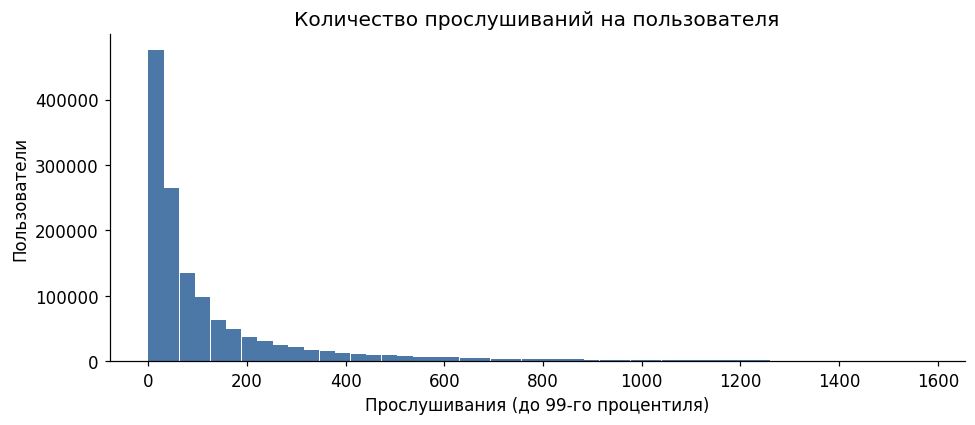

В данных 1,373,221 пользователей. Медиана — 55 прослушиваний, среднее — 162.1.
Выше границы графика находятся 13,723 пользователей.


In [3]:
eda_tables = get_eda_tables(items, events)
user_activity = eda_tables["user_activity"]
display(user_activity["listens"].describe(percentiles=[0.5, 0.9, 0.99]).to_frame())
plot_user_activity(user_activity)
plt.show()
limit = user_activity["listens"].quantile(0.99)
print("В данных {:,} пользователей. Медиана — {:.0f} прослушиваний, среднее — {:.1f}.".format(
    len(user_activity), user_activity["listens"].median(), user_activity["listens"].mean()))
print("Выше границы графика находятся {:,} пользователей.".format(int((user_activity["listens"] > limit).sum())))

Наиболее популярные треки по числу прослушиваний во всём предоставленном
наборе. Это описательная статистика; при построении рекомендаций популярность
будет рассчитана заново только на тренировочном периоде.

,item_id,name,artist_names,listen_count
0,53404,Smells Like Teen Spirit,[Nirvana],111062
1,33311009,Believer,[Imagine Dragons],106921
2,178529,Numb,[Linkin Park],101924
3,35505245,I Got Love,"[Miyagi & Эндшпиль, Рем Дигга]",99490
4,65851540,Юность,[Dabro],86670
5,24692821,Way Down We Go,[KALEO],86246
6,32947997,Shape of You,[Ed Sheeran],85886
7,51241318,In The End,"[Tommee Profitt, Fleurie, Mellen Gi]",85244
8,795836,Shape Of My Heart,[Sting],85042
9,45499814,Life,[Zivert],84748


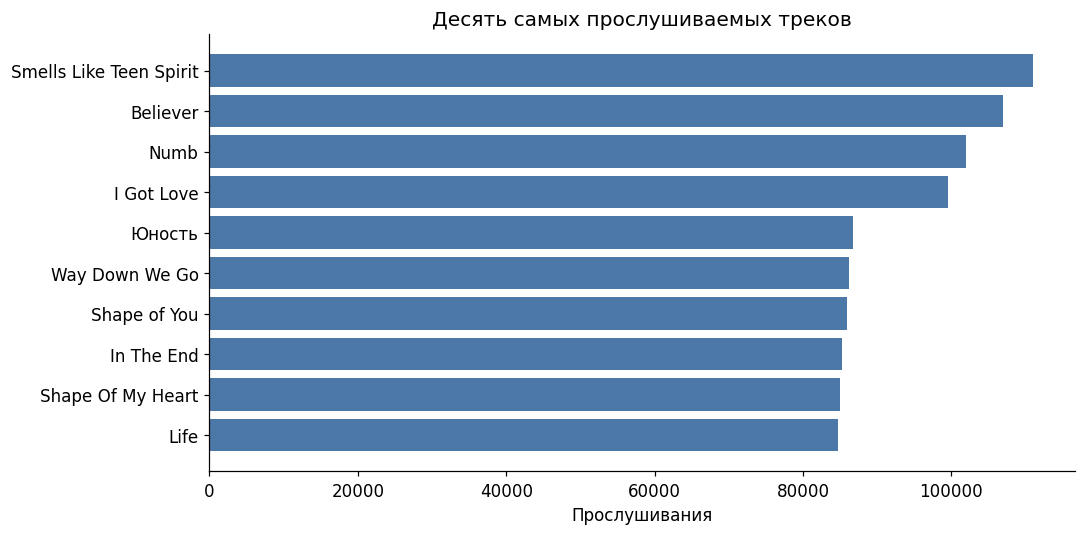

Больше всего прослушиваний у трека «Smells Like Teen Spirit»: 111,062.


In [15]:
display(eda_tables["top_tracks"][["item_id", "name", "artist_names", "listen_count"]].head(10))
plot_popular_tracks(eda_tables["top_tracks"])
plt.show()
top_track = eda_tables["top_tracks"].iloc[0]
print("Больше всего прослушиваний у трека «{}»: {:,}.".format(top_track["name"], int(top_track["listen_count"])))

Популярные жанры. Для каждого жанра суммируется число прослушиваний треков,
которые к нему относятся. У трека может быть несколько жанров, поэтому
эти суммы пересекаются и не являются долями единого целого.

,genre_id,name,listen_count,track_count
0,11,pop,55578312,166285
1,75,rap,37799821,128212
2,102,allrock,31092013,118509
3,20,ruspop,26626241,46707
4,3,rusrap,25303695,65958
5,68,electronics,20120981,114245
6,16,dance,16291557,51631
7,2,rusrock,13166147,36649
8,14,rock,12772644,55177
9,47,metal,12437375,72311


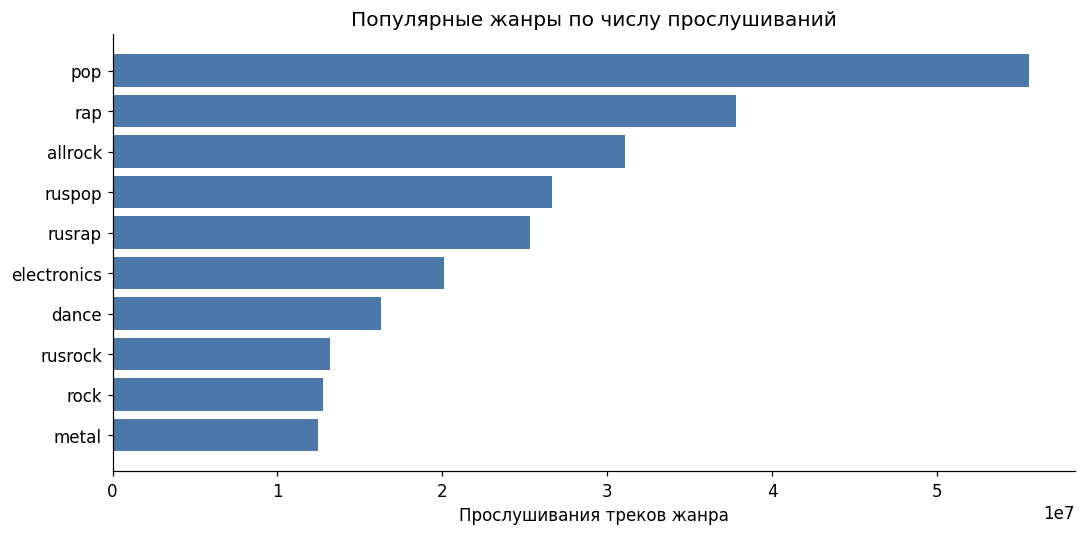

Больше всего прослушиваний пришлось на треки жанра «pop»: 55,578,312.


In [16]:
display(eda_tables["top_genres"].head(10))
plot_popular_genres(eda_tables["top_genres"])
plt.show()
if not eda_tables["top_genres"].empty:
    top_genre = eda_tables["top_genres"].iloc[0]
    print("Больше всего прослушиваний пришлось на треки жанра «{}»: {:,}.".format(
        top_genre["name"], int(top_genre["listen_count"])))

Треки без прослушиваний в предоставленной истории. Отсутствие событий не
означает отрицательную оценку: трек мог быть малоизвестен или недоступен
этим пользователям. Проверка относится ко всему каталогу `items`.

,group,tracks
0,Есть прослушивания,1000000
1,Нет прослушиваний,0


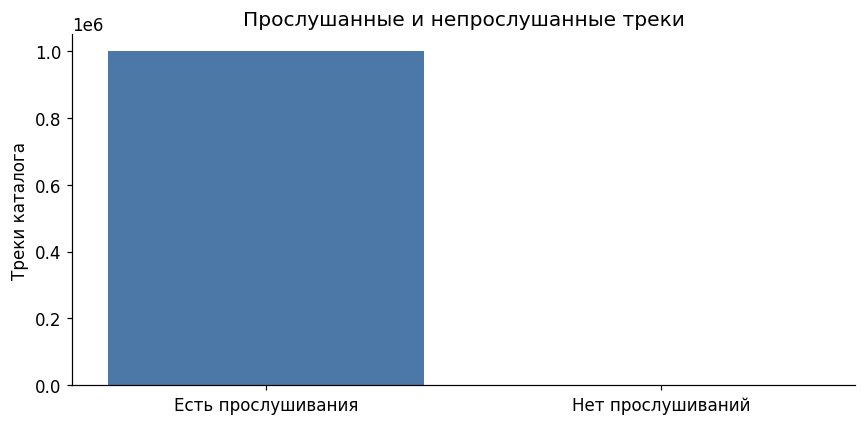

Без прослушиваний: 0 из 1,000,000 треков (0.00%).


,item_id,name,artist_names


In [17]:
display(eda_tables["track_coverage"])
plot_unheard_tracks(eda_tables["track_coverage"])
plt.show()
unheard_count = len(eda_tables["unheard_tracks"])
print("Без прослушиваний: {:,} из {:,} треков ({:.2%}).".format(unheard_count, len(items), unheard_count / len(items)))
display(eda_tables["unheard_tracks"][["item_id", "name", "artist_names"]].head(5))

# Преобразование данных

Подготовленные названия таблиц и колонок: `items` с ключом `item_id`,
`events` с полями `user_id`, `item_id`, `track_seq`, `started_at`.
Списки исполнителей, альбомов и жанров, а также прочие исходные свойства
треков сохраняются. Дополнительно сохранены читаемые названия и признаки
неизвестных атрибутов.

In [18]:
display(items[["item_id", "name", "artists", "albums", "genres"]].head(3))
event_preview = next(pq.ParquetFile(events).iter_batches(batch_size=3)).to_pandas(ignore_metadata=True)
display(event_preview)
assert pd.api.types.is_integer_dtype(items["item_id"])
assert pd.api.types.is_datetime64_any_dtype(event_preview["started_at"])

,item_id,name,artists,albums,genres
0,26,Complimentary Me,[16],"[3, 2490753]","[11, 21]"
1,38,Momma's Boy,[16],"[3, 2490753]","[11, 21]"
2,135,Atticus,[84],"[12, 214, 2490809]",[11]


,user_id,item_id,track_seq,started_at
0,6413,44136225,37,2022-10-31
1,6415,32038189,7,2022-12-06
2,6415,89977243,55,2022-12-25


# Сохранение данных

Сохраним данные в двух файлах в персональном S3-бакете по пути `recsys/data/`:
- `items.parquet` — все данные о музыкальных треках,
- `events.parquet` — все данные о взаимодействиях.

In [19]:
s3_client, s3_bucket = ensure_storage()
items_path = PREPARED_DIR / "items.parquet"
events_path = PREPARED_DIR / "events.parquet"
items.to_parquet(items_path, index=False)
assert Path(events).resolve() == events_path.resolve()
saved_rows = {"items": len(items), "events": pq.ParquetFile(events_path).metadata.num_rows}
print(upload_file(items_path, "recsys/data/items.parquet"))
print(upload_file(events_path, "recsys/data/events.parquet"))

s3://s3-student-mle-20260617-c4d98ba817-freetrack/recsys/data/items.parquet


s3://s3-student-mle-20260617-c4d98ba817-freetrack/recsys/data/events.parquet


# Очистка памяти

Перед этапом 3 освобожу подготовленные таблицы и EDA. Дальше заново прочитаю
данные из S3: это проверяет не только локальное сохранение, но и доступность
сохранённых результатов. Файл событий остаётся на диске; в памяти находится
только каталог и небольшие агрегаты. После перезапуска ядра нужно выполнить подготовку
вспомогательных файлов и импорты, затем продолжить с загрузки этапа 3.

In [20]:
del items, events, eda_tables, user_activity, prepared_summary, event_preview
gc.collect()

11202

# === ЭТАП 3 ===

# Загрузка данных

Загружаю именно сохранённые в S3 файлы. Данные не подменяются исходными
локальными таблицами. После скачивания проверю размеры и типы.

In [21]:
items_path = download_file("recsys/data/items.parquet", PREPARED_DIR / "items_from_s3.parquet")
events_path = download_file("recsys/data/events.parquet", PREPARED_DIR / "events_from_s3.parquet")
items = pd.read_parquet(items_path)
events = events_path

In [22]:
s3_events_summary = event_summary(events)
print("Из S3 прочитан каталог:", items.shape)
display(s3_events_summary)
if "saved_rows" in globals():
    assert len(items) == saved_rows["items"]
    assert int(s3_events_summary.iloc[0]["rows"]) == saved_rows["events"]
assert items["item_id"].is_unique

Из S3 прочитан каталог: (1000000, 14)


,rows,users,min_date,max_date
0,222629898,1373221,2022-01-01,2022-12-31


# Разбиение данных

Граница внешнего теста — **16 декабря 2022 года, не включительно для train**.
Так модель использует прошлое для прогноза будущих действий.

Для обучения ранжирования нужен отдельный внутренний период: ALS-кандидаты
и признаки рассчитываются по данным **до 9 декабря**, а таргеты — по событиям
**9–15 декабря**. Внешний тест не используется ни как таргет, ни для признаков.
После обучения ранжирования итоговая ALS переобучается на всём внешнем train.

Ранжирующая модель обучается на фиксированной случайной выборке до **30 000
пользователей** из внутреннего периода. Это ограничивает объём таблицы
кандидатов и время расчёта. Выборка детерминированная, гиперпараметры не
подбираются. Сначала обучу ранжирование, чтобы не хранить две ALS-модели
одновременно.

In [23]:
all_user_ids = get_user_ids(events)
train_events, test_events = split_events(events, cutoff=CUTOFF)
del events
gc.collect()
train_summary = event_summary(train_events)
test_summary = event_summary(test_events)
display(pd.concat({"train": train_summary, "test": test_summary}).reset_index(level=1, drop=True))
assert train_summary.iloc[0]["max_date"] < pd.Timestamp(CUTOFF)
assert test_summary.iloc[0]["min_date"] >= pd.Timestamp(CUTOFF)

,rows,users,min_date,max_date
train,208731252,1342566,2022-01-01,2022-12-15
test,13898646,783525,2022-12-16,2022-12-31


In [24]:
ranker, ranker_info = train_ranker(
    items, train_events, output_dir=RECOMMENDATIONS_DIR,
    user_limit=RANKER_USER_LIMIT,
)
display(pd.Series(ranker_info, name="обучение ранжирования").to_frame())

Подготовка уникальных пар для CSR: events_from_s3_before_20221216_before_20221209.parquet


CSR готова: 1321308 пользователей, 999049 треков, 200834917 пар.


  0%|          | 0/15 [00:00<?, ?it/s]

  7%|▋         | 1/15 [00:07<01:43,  7.39s/it]

 13%|█▎        | 2/15 [00:14<01:35,  7.34s/it]

...

25:	total: 6.13s	remaining: 17.4s


50:	total: 12s	remaining: 11.6s


75:	total: 17.9s	remaining: 5.64s


99:	total: 23.4s	remaining: 0us


,обучение ранжирования
base_end_exclusive,2022-12-09
labels_end_exclusive,2022-12-16
sampled_users,30000
training_users,8388
training_candidates,962138
positive_candidates,15225
features,"[als_score, item_popularity, user_activity, genre_count]"


# Топ популярных

В базовой рекомендации популярность — число **уникальных слушателей** трека
в train. Повторные прослушивания одного человека не увеличивают этот счётчик.
При одинаковой популярности использую порядок по `item_id`.

In [25]:
top_popular = get_popular_items(train_events, limit=1000)
display(top_popular.head(10).merge(items[["item_id", "name"]], on="item_id", how="left"))

,item_id,score,rank,name
0,53404,110026.0,1,Smells Like Teen Spirit
1,33311009,101076.0,2,Believer
2,178529,100866.0,3,Numb
3,35505245,95523.0,4,I Got Love
4,24692821,84153.0,5,Way Down We Go
5,795836,83749.0,6,Shape Of My Heart
6,6705392,80608.0,7,Seven Nation Army
7,32947997,80243.0,8,Shape of You
8,37384,79512.0,9,Zombie
9,45499814,78564.0,10,Life


In [26]:
print("В общем списке популярных рекомендаций {} треков.".format(len(top_popular)))

В общем списке популярных рекомендаций 1000 треков.


# Персональные

Использую ALS с фиксированными параметрами: 32 фактора, 15 итераций,
регуляризация 0.1. Взаимодействия бинарные, уверенность для известной пары
равна 20. Для большого каталога кандидаты ищутся приближённо через FAISS HNSW,
после чего их оценки пересчитываются скалярным произведением факторов ALS.
Это позволяет не создавать плотную матрицу «все пользователи × все треки».

In [27]:
als_data = fit_als(train_events)
print("Матрица взаимодействий:", als_data.matrix.shape)
print("Ненулевых пар:", als_data.matrix.nnz)
print("Факторы пользователей:", als_data.model.user_factors.shape)
print("Факторы треков:", als_data.model.item_factors.shape)

Подготовка уникальных пар для CSR: events_from_s3_before_20221216.parquet


CSR готова: 1342566 пользователей, 999695 треков, 208731252 пар.


  0%|          | 0/15 [00:00<?, ?it/s]

  7%|▋         | 1/15 [00:07<01:47,  7.66s/it]

 13%|█▎        | 2/15 [00:15<01:39,  7.65s/it]

...

 87%|████████▋ | 13/15 [01:43<00:17,  8.93s/it]

 93%|█████████▎| 14/15 [01:54<00:09,  9.37s/it]

100%|██████████| 15/15 [02:04<00:00,  9.75s/it]

100%|██████████| 15/15 [02:04<00:00,  8.32s/it]

Матрица взаимодействий: (1342566, 999695)
Ненулевых пар: 208731252
Факторы пользователей: (1342566, 32)
Факторы треков: (999695, 32)


In [28]:
test_users = pd.Index(get_user_ids(test_events))
cold_users_count = int((pd.Index(als_data.user_ids).get_indexer(test_users) < 0).sum())
print("В тесте {:,} пользователей без истории train. Для них используется топ популярных.".format(cold_users_count))

В тесте 30,655 пользователей без истории train. Для них используется топ популярных.


# Похожие

Для онлайн-рекомендаций подготовлю по 10 соседей каждого трека, известного
ALS. Близость определяется косинусным сходством факторов, сам исходный трек
из списка исключается. Сохранение соседей выполняется порциями вместе
с остальными рекомендациями ниже.

In [29]:
print("Для расчёта похожих треков доступны {:,} объектов ALS.".format(len(als_data.item_ids)))

Для расчёта похожих треков доступны 999,695 объектов ALS.


In [30]:
# Готовые списки соседей будут сохранены в similar.parquet при общем сохранении.
# В них используются исходные идентификаторы item_id_1 и item_id_2.

# Построение признаков

Ранжирование использует четыре признака:

- `als_score` — оценка ALS для пары пользователь–трек;
- `item_popularity` — логарифм числа уникальных слушателей трека;
- `user_activity` — логарифм числа известных пользователю треков;
- `genre_count` — количество жанров у трека.

При обучении эти признаки рассчитаны только по истории до 9 декабря.
Для итогового применения используются данные до 16 декабря. Значения
популярности и активности из EDA всего набора в модель не передаются.

In [31]:
display(pd.DataFrame({"признак": ranker_info["features"]}))

,признак
0,als_score
1,item_popularity
2,user_activity
3,genre_count


In [32]:
feature_importance = pd.DataFrame({
    "признак": ranker.feature_names_,
    "важность": ranker.get_feature_importance(type="PredictionValuesChange"),
}).sort_values("важность", ascending=False)
display(feature_importance)
print("Важность показывает вклад признака в изменение предсказаний модели.")

,признак,важность
1,item_popularity,39.647209
0,als_score,27.758245
3,genre_count,22.958040
2,user_activity,9.636506


Важность показывает вклад признака в изменение предсказаний модели.


# Ранжирование рекомендаций

Ранжирующая модель CatBoostRanker уже обучена на внутреннем периоде.
Для каждого пользователя объединяются 100 ALS-кандидатов и 20 популярных
треков, после чего сохраняются 20 итоговых рекомендаций. Для персонального
ALS-списка отдельно сохраняются 50 треков. Для холодных пользователей
используются популярные треки.

Расчёт идёт порциями. Результаты сначала записываются в локальные Parquet,
затем загружаются в персональный S3-бакет.

In [33]:
artifact_info = save_recommendations(
    items, train_events, als_data, ranker, RECOMMENDATIONS_DIR,
    all_user_ids=all_user_ids,
)
display(pd.Series(artifact_info, name="сохранённые рекомендации").to_frame())
for filename in ["top_popular.parquet", "personal_als.parquet", "similar.parquet", "recommendations.parquet"]:
    print(upload_file(RECOMMENDATIONS_DIR / filename, "recsys/recommendations/" + filename))

Рекомендации: 512 из 1373221 пользователей


Рекомендации: 51200 из 1373221 пользователей


Рекомендации: 102400 из 1373221 пользователей


Рекомендации: 153600 из 1373221 пользователей


Рекомендации: 204800 из 1373221 пользователей


...

,сохранённые рекомендации
users,1373221
cold_users,30655
rows,"{'top_popular': 1000, 'personal_als': 68661050, 'recommendations':..."
candidate_search,"FAISS HNSW32, efConstruction=80, efSearch=64; для <=1000 треков то..."


s3://s3-student-mle-20260617-c4d98ba817-freetrack/recsys/recommendations/top_popular.parquet


s3://s3-student-mle-20260617-c4d98ba817-freetrack/recsys/recommendations/personal_als.parquet


s3://s3-student-mle-20260617-c4d98ba817-freetrack/recsys/recommendations/similar.parquet


s3://s3-student-mle-20260617-c4d98ba817-freetrack/recsys/recommendations/recommendations.parquet


In [34]:
for filename in ["top_popular.parquet", "personal_als.parquet", "similar.parquet", "recommendations.parquet"]:
    import pyarrow.parquet as pq
    parquet_file = pq.ParquetFile(RECOMMENDATIONS_DIR / filename)
    print(filename, "— строк:", parquet_file.metadata.num_rows)
    display(parquet_file.read_row_group(0).slice(0, 3).to_pandas())

top_popular.parquet — строк: 1000


,item_id,score,rank
0,53404,110026.0,1
1,33311009,101076.0,2
2,178529,100866.0,3


personal_als.parquet — строк: 68661050


,user_id,item_id,score,rank
0,0,19972786,0.142027,1
1,0,17856052,0.138076,2
2,0,6006252,0.137569,3


similar.parquet — строк: 9996950


,item_id_1,item_id_2,score,rank
0,26,20111365,0.894176,1
1,26,4850799,0.871979,2
2,26,22836932,0.859886,3


recommendations.parquet — строк: 27464420


,user_id,item_id,score,rank
0,0,9980494,0.506668,1
1,0,9439513,0.454232,2
2,0,2198468,0.392174,3


# Оценка качества

Сравниваю три вида рекомендаций на одинаковых тестовых пользователях, `k=20`:

- **Recall@20** — доля уникальных треков пользователя из test, найденных в топ-20;
- **Precision@20** — число попаданий в test, делённое на 20;
- **Coverage@20** — доля всего каталога, встретившаяся в рекомендациях тестовой группы;
- **Novelty@20** — средняя по пользователям доля рекомендованных треков, которых
  не было в их train-истории.

Recall и precision усредняются по пользователям. Повторы в целевой выборке
считаются одним треком. Холодные пользователи не отбрасываются: для них
используется топ популярных. Поскольку повторное прослушивание допустимо,
знакомые треки остаются в рекомендациях, и novelty может быть меньше единицы.

In [35]:
metrics = evaluate_recommendations(
    items, train_events, test_events, RECOMMENDATIONS_DIR,
    k=K, user_limit=EVALUATION_USER_LIMIT, als_data=als_data,
)
display(metrics.round(5))
metrics.to_csv("metrics.csv", encoding="utf-8")

Подготовка уникальных пар для CSR: events_from_s3_from_20221216.parquet


CSR готова: 783525 пользователей, 1000000 треков, 13898646 пар.


,recall,precision,coverage,novelty,users,k
method,,,,,,
Популярные,0.00780,0.00518,0.00002,0.93937,783525,20
ALS,0.02129,0.00772,0.01778,0.77558,783525,20
Ранжирование,0.02312,0.00946,0.03220,0.85405,783525,20


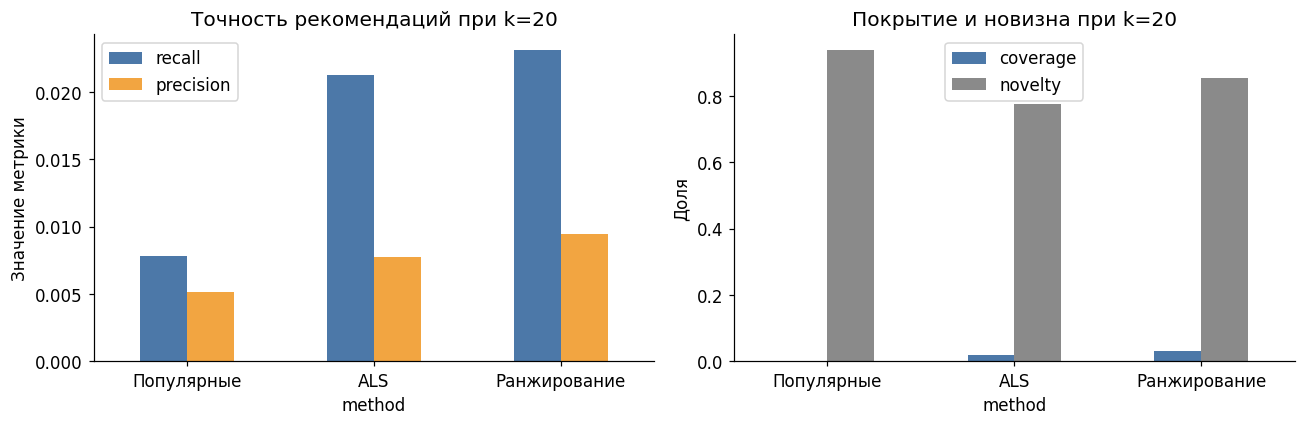

55

In [36]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4))
metrics[["recall", "precision"]].plot.bar(ax=axes[0], color=["#4C78A8", "#F2A541"], rot=0)
axes[0].set(title="Точность рекомендаций при k=20", ylabel="Значение метрики")
metrics[["coverage", "novelty"]].plot.bar(ax=axes[1], color=["#4C78A8", "#8A8A8A"], rot=0)
axes[1].set(title="Покрытие и новизна при k=20", ylabel="Доля")
figure.tight_layout()
plt.show()
del als_data
gc.collect()

# === Выводы, метрики ===

Построен воспроизводимый прототип: подготовка данных, популярные треки,
ALS, похожие треки и ранжирование. Параметры зафиксированы без fine-tuning.
Качество оценивается по будущему периоду; выводы ниже рассчитываются
непосредственно из полученной таблицы метрик.

Ограничения: приближённый поиск кандидатов может пропустить часть треков;
ранжирование обучается на ограниченной выборке пользователей; офлайн-метрики
не заменяют проверку сервиса с реальными пользователями.

In [37]:
best_method = metrics["recall"].idxmax()
print("Наибольший recall@{} получен у метода «{}»: {:.5f}.".format(K, best_method, metrics.loc[best_method, "recall"]))
for method, row in metrics.iterrows():
    print("{}: precision={:.5f}, recall={:.5f}, coverage={:.2%}, novelty={:.2%}.".format(
        method, row["precision"], row["recall"], row["coverage"], row["novelty"]))
recall_difference = metrics.loc["Ранжирование", "recall"] - metrics.loc["ALS", "recall"]
print("Изменение recall после ранжирования относительно ALS: {:+.5f}.".format(recall_difference))

Наибольший recall@20 получен у метода «Ранжирование»: 0.02312.
Популярные: precision=0.00518, recall=0.00780, coverage=0.00%, novelty=93.94%.
ALS: precision=0.00772, recall=0.02129, coverage=1.78%, novelty=77.56%.
Ранжирование: precision=0.00946, recall=0.02312, coverage=3.22%, novelty=85.40%.
Изменение recall после ранжирования относительно ALS: +0.00183.


In [38]:
print("Сохранены данные recsys/data/items.parquet и recsys/data/events.parquet.")
print("В recsys/recommendations/ сохранены top_popular.parquet, personal_als.parquet, similar.parquet и recommendations.parquet.")
print("Следующий этап — сервис выдачи рекомендаций и его тестирование.")

Сохранены данные recsys/data/items.parquet и recsys/data/events.parquet.
В recsys/recommendations/ сохранены top_popular.parquet, personal_als.parquet, similar.parquet и recommendations.parquet.
Следующий этап — сервис выдачи рекомендаций и его тестирование.
